<!-- reader-content -->

# Pulses, leakage, and readout

<!-- notebook-download -->

How does pulse duration change leakage, and how does the qubit state appear in
resonator readout? Use one coupled model for both experiments, and read the
pulses as gates between them. Frequencies are in GHz and times in ns.

## Define the chip

The transmon couples to a 6.8 GHz resonator with a 1 MHz linewidth, and separate
charge lines address the qubit and the readout.

In [1]:
import numpy as np
from quchip import (
    RWA, Capacitive, ChargeDrive, Chip, DuffingTransmon,
    Gaussian, GaussianEdge, QuantumSequence, Resonator,
)

qubit = DuffingTransmon(freq=5.0, anharmonicity=-0.30, levels=6, label="q")
readout = Resonator(freq=6.8, levels=10, internal_quality_factor=6800, label="r")
chip = Chip(
    [qubit, readout], [Capacitive(qubit, readout, g=0.060, label="qr")],
    frame="rotating", approximation=RWA(),
)

qubit_line = ChargeDrive(qubit, label="qubit-charge")
readout_line = ChargeDrive(readout, label="readout-charge")
_ = chip.wire(qubit_line, readout_line)

## Compare a short and a long qubit pulse

`chip.rotation_amplitude()` gives each Gaussian the amplitude of a π
rotation, from the envelope area and the dressed matrix element of the qubit
line. The short pulse's spectral width is comparable to the separation
between the dressed 0→1 and 1→2 transitions, so the four-times-longer pulse
is more selective.

In [2]:
f01 = float(chip.freq(qubit))
f12 = float(chip.transition_frequency(qubit, 1, 2))
drive_durations = 3 / (np.pi * abs(f12 - f01)) * np.array([1.0, 4.0])

drive_pulses = []
for duration in drive_durations:
    shape = Gaussian(duration=duration, sigmas=3.0)
    amplitude = chip.rotation_amplitude(qubit, qubit_line, shape)
    drive_pulses.append(Gaussian(duration=duration, sigmas=3.0, amplitude=amplitude))

Schedule the short pulse, then change its duration and amplitude
together. Each batch member starts in dressed |0,0⟩ and uses the same
time grid.

In [3]:
drive_sequence = QuantumSequence(chip)
drive = drive_sequence.schedule(qubit_line, envelope=drive_pulses[0], freq=f01)
drive_times = np.linspace(0, drive_durations[-1], 601)

drive_batch = drive_sequence.simulate_batch(
    drive_sequence.zip(
        drive.vary("duration", drive_durations),
        drive.vary("amplitude", [pulse.amplitude for pulse in drive_pulses]),
    ),
    tlist=drive_times,
    initial_state=chip.state({qubit: 0, readout: 0}),
    progress=False,
)

Read the populations of |0⟩, |1⟩, and |2⟩ in arrays indexed by
`(level, pulse, time)`.

In [4]:
drive_populations = np.asarray([
    drive_batch.population(qubit, level) for level in range(3)
]).real

<details>
<summary>Plot the envelopes and populations</summary>

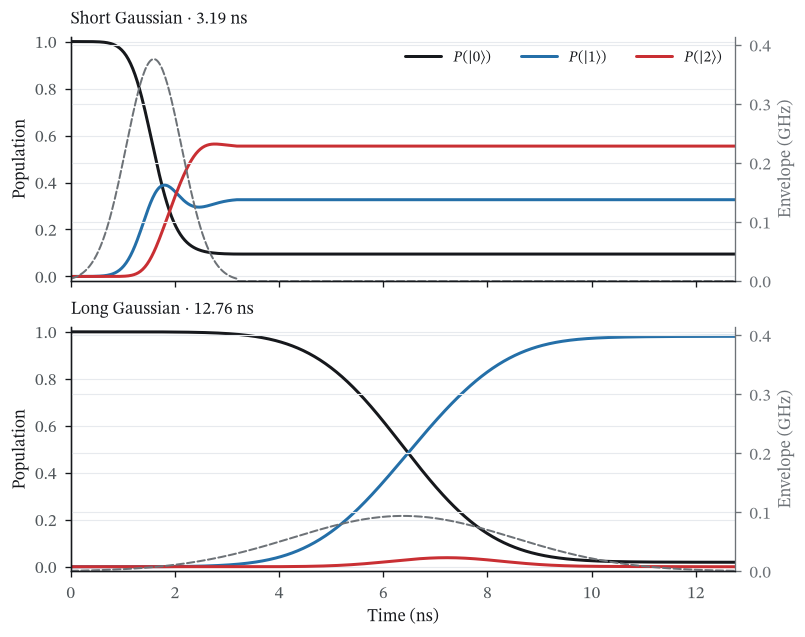

In [5]:
import shutil
from pathlib import Path
import matplotlib.pyplot as plt

# In a quchip checkout, use the documentation style and save the figures there.
docs = Path("../docs")
if docs.is_dir():
    plt.style.use(docs / "_static/quchip.mplstyle")
plt.rcParams["text.usetex"] = bool(shutil.which("latex"))

colors = ("#16181C", "#246FA8", "#C92F33")

figure, axes = plt.subplots(2, 1, figsize=(6.6, 5.2), sharex=True, layout="constrained")
for index, (axis, name, envelope) in enumerate(zip(axes, ("Short", "Long"), drive_pulses)):
    for level, color in enumerate(colors):
        axis.plot(drive_times, drive_populations[level, index], color=color,
                  lw=1.8, label=fr"$P(|{level}\rangle)$")
    pulse_axis = axis.twinx()
    pulse_axis.plot(drive_times, np.where(drive_times <= envelope.duration,
                    envelope.sample(drive_times, real=True), 0.0),
                    color="#6D7277", ls="--", lw=1.2)
    pulse_axis.set(ylabel="Envelope (GHz)", ylim=(0, 1.1 * drive_pulses[0].amplitude))
    pulse_axis.spines["right"].set_visible(True)
    pulse_axis.spines["right"].set_color("#6D7277")
    pulse_axis.yaxis.label.set_color("#6D7277")
    pulse_axis.tick_params(axis="y", colors="#6D7277")
    axis.set(ylabel="Population", ylim=(-0.02, 1.02), xlim=(0, drive_times[-1]))
    axis.set_title(fr"{name} Gaussian $\cdot$ {envelope.duration:.2f} ns")

axes[0].legend(ncol=3, loc="upper right", fontsize=9)
axes[1].set_xlabel("Time (ns)")

if docs.is_dir():
    figure.savefig(docs / "images/hello_qubit_drive_leakage.svg")
    figure.savefig(docs / "images/hello_qubit_drive_leakage.png")
plt.show()

</details>

```{figure} ../images/hello_qubit_drive_leakage.svg
:alt: Short and long Gaussian envelopes with ground, excited, and leakage populations over time.

Dashed grey curves show the drive envelopes. The short pulse populates |2⟩,
and the longer pulse leaves most population in |1⟩.
[PDF](../images/hello_qubit_drive_leakage.pdf)
```

In [6]:
for index, name in enumerate(("Short", "Long")):
    print(
        f"{name}: final P1 = {drive_populations[1, index, -1]:.1%}; "
        f"peak P2 = {drive_populations[2, index].max():.1%}"
    )

Short: final P1 = 32.7%; peak P2 = 56.4%
Long: final P1 = 98.1%; peak P2 = 3.8%


Equal pulse area does not guarantee equal inversion in a multilevel system,
and the smaller peak P2 shows why the longer pulse comes closer to the target.

## Read the pulses as gates

`subspace_propagator(qubit)` runs a pulse from each dressed qubit state, |0⟩
and |1⟩, with the resonator empty. It returns the 2 × 2 matrix in the frame
of the dressed frequencies and the leakage of each input out of these
states. Since the charge operator Q of the line has the dressed matrix element
⟨1|Q|0⟩ ≈ i on the 0→1 transition, a real π pulse aims at −iY up to a global
phase. `fidelity()` gives the average gate fidelity, which counts
the leakage. A propagator describes the Hamiltonian alone, so the call
leaves out the resonator loss.

In [7]:
gates = {}
for name, pulse in zip(("Short", "Long"), drive_pulses):
    gate_sequence = QuantumSequence(chip)
    _ = gate_sequence.schedule(qubit_line, envelope=pulse, freq=f01)
    gates[name] = gate_sequence.subspace_propagator(qubit)

minus_iy = np.array([[0, -1], [1, 0]])
for name, gate in gates.items():
    print(f"{name}: fidelity to −iY = {float(gate.fidelity(minus_iy)):.3f}; "
          f"leakage from |0⟩ = {float(gate.leakage[0]):.1e}")

Short: fidelity to −iY = 0.422; leakage from |0⟩ = 5.8e-01
Long: fidelity to −iY = 0.988; leakage from |0⟩ = 4.3e-05


The short pulse moves most of |0⟩ out of the qubit states, while the long
pulse leaks little, so most of its error is coherent. The drive also couples
|1⟩ to |2⟩, which shifts the 0→1 transition during the pulse, and the result
is a nearly π rotation with a tilted axis and a small angle error. The amplitude is a
first guess for a calibration.

## Read out the prepared qubit state

Now drive the resonator, whose frequency depends on the qubit state. Use a
tone halfway between the dressed resonances for qubit states |0⟩ and |1⟩,
with the same RWA Hamiltonian as the simulation. To see the IQ response in
the drive frame, set `reference_freq` to the carrier.

In [8]:
readout_dressed = chip.resolve(frame="lab").dress()
readout_energies = readout_dressed.dressed_eigenvalues
readout_frequencies = [
    float(readout_energies[(level, 1)] - readout_energies[(level, 0)])
    for level in (0, 1)
]
readout_carrier = np.mean(readout_frequencies)
readout.reference_freq = readout_carrier

readout_pulse = GaussianEdge(duration=900.0, edge_duration=40.0, sigmas=3, amplitude=0.0012)
readout_sequence = QuantumSequence(chip)
_ = readout_sequence.schedule(readout_line, envelope=readout_pulse, freq=readout_carrier)

Apply the same pulse to dressed |0,0⟩ and |1,0⟩ states that are prepared
separately, so the readout comparison does not inherit the leakage of the
previous experiment. Follow the two IQ pointers during the 900 ns
readout pulse.

In [9]:
readout_times = np.linspace(0, 900, 181)

readout_batch = readout_sequence.simulate_batch(
    readout_sequence.vary(
        "initial_state",
        [readout_dressed.eigenstates[readout_dressed.state_map[(level, 0)]]
         for level in (0, 1)],
        name="prepared_qubit",
    ),
    tlist=readout_times,
    e_ops=chip.e_ops(r="a"),
    progress=False,
)

`expect("r")` returns the requested α(t) = ⟨a⟩. Compare the two complex
responses and their separation over time.

In [10]:
alpha = np.asarray(readout_batch.expect("r"), dtype=complex)
iq_separation = np.abs(alpha[0] - alpha[1])

<details>
<summary>Plot the readout pulse and IQ response</summary>

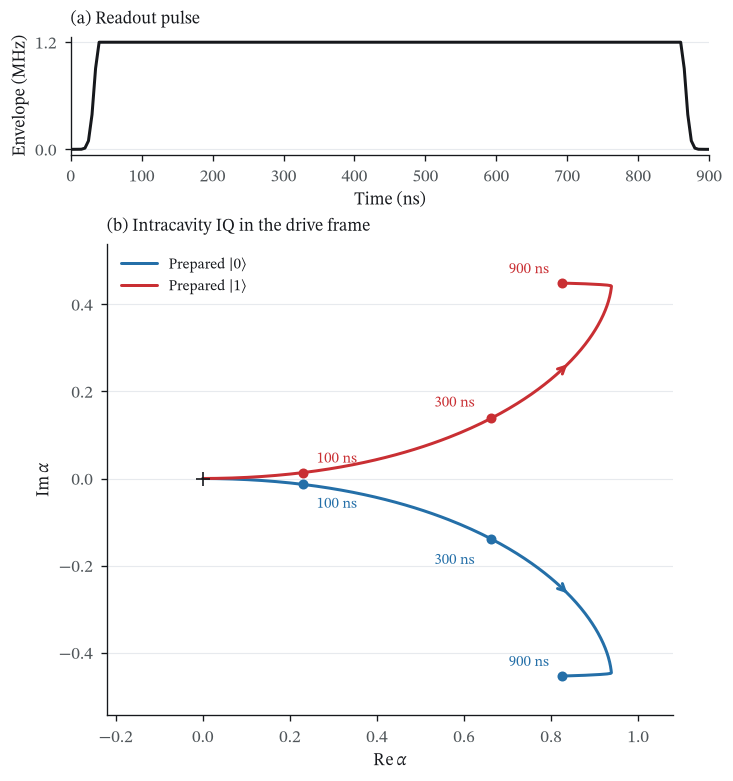

In [11]:
figure, (time_axis, iq_axis) = plt.subplots(2, 1, figsize=(6.0, 6.4),
                                         height_ratios=(0.55, 2.2), layout="constrained")

time_axis.plot(readout_times, 1000 * readout_pulse.sample(readout_times, real=True),
               color="#16181C", lw=1.8)
time_axis.set(xlabel="Time (ns)", ylabel="Envelope (MHz)", xlim=(0, 900), yticks=[0, 1.2])
time_axis.set_title("(a) Readout pulse")

for level, color in enumerate(("#246FA8", "#C92F33")):
    path = alpha[level]
    iq_axis.plot(path.real, path.imag, color=color, lw=1.8,
                 label=fr"Prepared $|{level}\rangle$")
    for time in (100, 300, 900):
        point = path[np.searchsorted(readout_times, time)]
        iq_axis.plot(point.real, point.imag, "o", color=color, ms=5)
        offset = {100: (8, -14 if level == 0 else 6), 300: (-10, -15 if level == 0 else 7), 900: (-8, 6)}
        iq_axis.annotate(f"{time} ns", (point.real, point.imag), xytext=offset[time],
                         textcoords="offset points", ha="left" if time == 100 else "right",
                         color=color, fontsize=9)
    start, end = path[90], path[96]
    iq_axis.annotate("", (end.real, end.imag), (start.real, start.imag),
                     arrowprops={"arrowstyle": "->", "color": color, "lw": 1.8})

iq_axis.plot(0, 0, "+", color="#16181C", ms=8)
iq_axis.set(xlabel=r"$\mathrm{Re}\,\alpha$", ylabel=r"$\mathrm{Im}\,\alpha$",
            xlim=(-0.22, 1.15 * alpha.real.max()), ylim=(1.2 * alpha.imag.min(), 1.2 * alpha.imag.max()))
iq_axis.set_title("(b) Intracavity IQ in the drive frame")
iq_axis.set_aspect("equal", adjustable="box")
iq_axis.legend(fontsize=9, loc="upper left")

if docs.is_dir():
    figure.savefig(docs / "images/hello_dispersive_readout_iq.svg")
    figure.savefig(docs / "images/hello_dispersive_readout_iq.png")
plt.show()

</details>

```{figure} ../images/hello_dispersive_readout_iq.svg
:alt: Readout pulse with two drive-frame IQ trajectories marked at 100, 300, and 900 ns.
:class: wide-figure

Above: the readout pulse envelope. Below: the
IQ pointers traced during readout, with time markers and arrows showing
the direction of motion. The cross marks zero field.
[PDF](../images/hello_dispersive_readout_iq.pdf)
```

The same drive produces distinguishable mean fields for the two qubit
states, as intracavity responses rather than a single-shot fidelity
estimate.

<details>
<summary>Numerical checks</summary>

In [12]:
from quchip import check_truncation

for result in (*drive_batch, *readout_batch):
    top_levels = check_truncation(result, threshold=1.0)
    assert max(top_levels.values()) < 1e-3

final_p1, peak_p2 = drive_populations[1, :, -1], drive_populations[2].max(axis=-1)
assert final_p1[1] > 0.9 and peak_p2[1] < 0.25 * peak_p2[0]
long_error = 1 - float(gates["Long"].fidelity(minus_iy))
assert float(gates["Short"].leakage[0]) > 0.5 and long_error > 10 * float(gates["Long"].leakage[0])
assert readout_batch[0].solver == "mesolve" and iq_separation[-1] > 0.01

</details>

To remove the photons that stay in the resonator after the pulse, see the
[resonator depletion study](../studies/resonator-depletion.md). To read a
prepared state through the fridge wiring, continue with
[qubit readout through the fridge](steady-state-and-vna.md#read-a-prepared-qubit-through-the-same-line).